# Cross-Scale Unembedding Analysis: Walkthrough

This notebook accompanies *From Local Density to Lexical Features: A Cross-Scale Study of Unembedding Spaces* (Dong, Hitzler, Vasserman; MIWAI 2026, LNCS 17147, pp. 160–175, [doi:10.1007/978-981-92-6513-8_13](https://doi.org/10.1007/978-981-92-6513-8_13)).

It has two parts:

1. **Results from tracked data.** Sections 1–5 rebuild the paper's main tables and cross-scale curves from the compact result files in `res/`. They run on a CPU in a few seconds and need no model weights.
2. **Running the pipeline.** Section 6 shows how to recompute everything from an unembedding matrix with the `crossscale` package. It needs the exported model tensors and a CUDA GPU with cuML, so it is disabled by default.

GPT-oss-20B permutation-control values in this notebook use the corrected data described in the [README erratum](README.md#erratum).

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from crossscale.metrics.orthographic import (
    compute_cluster_morphology_score,
    kondrak_trigram_similarity,
)
from crossscale.metrics.script_entropy import (
    dominant_script,
    entropy_from_distribution,
    normalized_entropy,
)
from crossscale.statistics_pipeline import MAEStatistic, R2Statistic, SpearmanStatistic

RESULTS = Path("res/paper_results")
SPECTRUM = Path("res/spectrum_analysis")
CORRECTIONS = RESULTS / "corrections" / "gpt-oss"

MODELS = {
    "mistralai_Mistral-7B-v0.1": "Mistral-7B",
    "mistralai_Mixtral-8x7B-v0.1": "Mixtral-8x7B",
    "gpt-oss": "GPT-oss-20B",
}

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

## 1. Method in one line

For a model with unembedding matrix $W$, each scale $k$ gives one observation

$$y_{\theta,m}(k) = A_m\big(C_\theta(\mathrm{PCA}_k(W))\big),$$

where $\mathrm{PCA}_k$ keeps the first $k$ principal components, $C_\theta$ is HDBSCAN on row-L2-normalized vectors with $(\texttt{min\_cluster\_size}, \texttt{min\_samples}) = (5, 5)$, and $A_m$ averages a lexical metric over the non-noise clusters with equal weight. The two metrics are Orthographic Similarity (O-S) and Multi-Script Entropy (MS-E).

![pipeline](assets/pipeline.png)

## 2. Candidate scales (Table 1)

Scales come from the singular-value spectrum of $W$: elbow points of the log spectrum, cumulative-energy thresholds, and the full dimension.

In [2]:
scale_rows = []
for model, label in MODELS.items():
    frame = pd.read_csv(SPECTRUM / model / "candidate_scales.csv")
    for source, group in frame.groupby("sources"):
        scale_rows.append({"model": label, "source": source, "scales": ", ".join(map(str, group["scale"]))})
pd.DataFrame(scale_rows).pivot(index="model", columns="source", values="scales").loc[list(MODELS.values())]

source,elbow,energy,full_dimension
model,,,
Mistral-7B,"5, 142, 3938, 4088","997, 2084, 3031, 3459",4096
Mixtral-8x7B,"8, 158, 3957, 4093","1111, 2156, 3052, 3457",4096
GPT-oss-20B,"6, 182, 466, 2868","739, 1591, 2264, 2532",2880


## 3. The two lexical metrics

**O-S** is the mean pairwise Kondrak trigram similarity (N-DIST) inside a cluster, compared case-insensitively. Clusters with more than 512 tokens use a fixed-seed sample of pairs.

**MS-E** labels each token with its dominant Unicode script and takes the Shannon entropy of the script distribution inside a cluster. Table 2 divides it by $\log|S|$, where $S$ is the set of scripts seen in the vocabulary.

In [3]:
pairs = [("running", "runner"), ("▁run", "run"), ("hello", "world"), ("Привет", "привет")]
display(pd.DataFrame(
    [{"a": a, "b": b, "kondrak_similarity": kondrak_trigram_similarity(a, b)} for a, b in pairs]
))

lexical_cluster = ["run", "running", "runner", "Run", "▁run"]
mixed_cluster = ["the", "der", "中文", "Привет", "アイ"]
for name, tokens in (("lexical", lexical_cluster), ("mixed-script", mixed_cluster)):
    scripts = Counter(dominant_script(token) for token in tokens)
    distribution = {script: count / len(tokens) for script, count in scripts.items()}
    entropy = entropy_from_distribution(distribution)
    print(
        f"{name:>12}: O-S = {compute_cluster_morphology_score(tokens):.3f}  "
        f"scripts = {dict(scripts)}  MS-E = {entropy:.3f} "
        f"(normalized with |S| = 30: {normalized_entropy(entropy, global_script_set_size=30):.3f})"
    )

,a,b,kondrak_similarity
0,running,runner,0.643
1,▁run,run,0.750
2,hello,world,0.200
3,Привет,привет,1.000


     lexical: O-S = 0.562  scripts = {'Latin': 5}  MS-E = 0.000 (normalized with |S| = 30: 0.000)
mixed-script: O-S = 0.000  scripts = {'Latin': 2, 'Han': 1, 'Cyrillic': 1, 'Katakana': 1}  MS-E = 1.332 (normalized with |S| = 30: 0.392)


## 4. Cross-scale curves and Table 2

Each curve below is one model's metric as a function of the PCA scale. The baseline uses deterministic full PCA. The randomized-PCA curve averages eight seeds. The token-permutation curve averages ten seeds of shuffling tokens across non-noise clusters while keeping every cluster size, so it shows what the metric looks like when cluster geometry is kept but lexical content is destroyed.

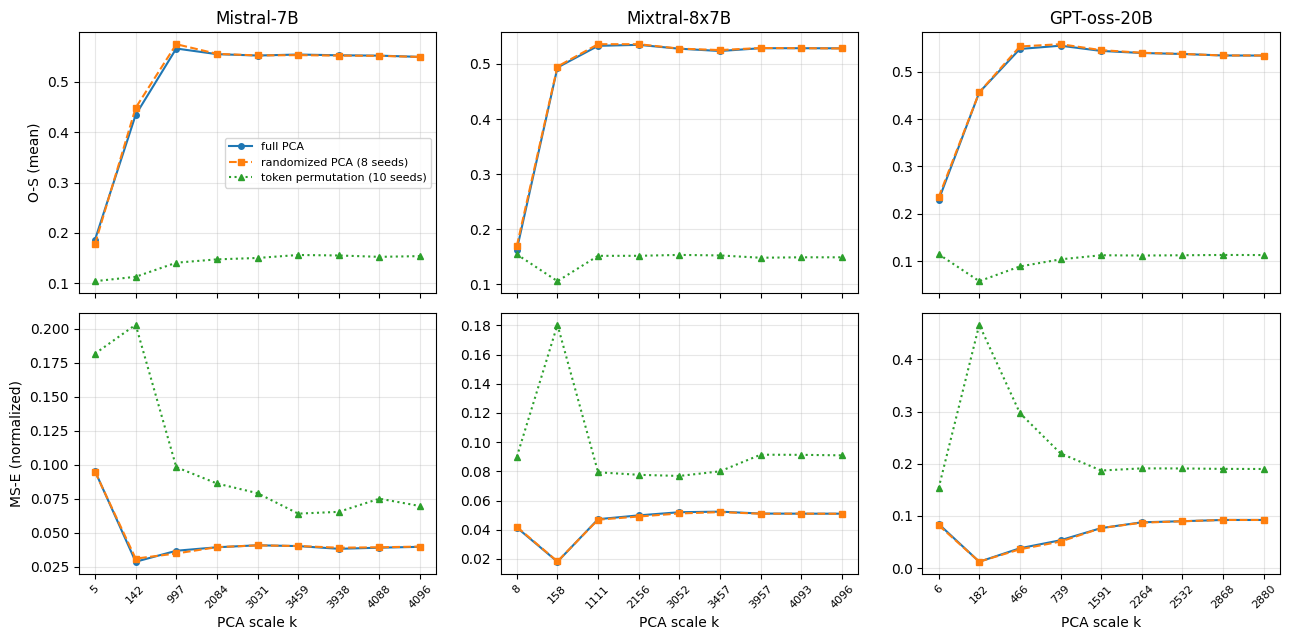

In [4]:
def scale_curve(frame, column, seed_column=None):
    if seed_column is not None:
        frame = frame.groupby("pca_dim", as_index=False)[column].mean()
    return frame.sort_values("pca_dim").set_index("pca_dim")[column].astype(float)


def load_curves(model):
    base = RESULTS / "baseline" / model
    seeds = RESULTS / "cross_seed" / model
    perm = RESULTS / "token_permutation" / model
    perm_os = pd.read_csv(perm / "kondrak_global_summary_all_seeds.csv")
    perm_mse = pd.read_csv(perm / "script_entropy_summary_all_seeds.csv")
    if model == "gpt-oss":
        perm_os = pd.read_csv(CORRECTIONS / "token_permutation_kondrak_global_summary_all_seeds.csv")
        perm_mse = pd.read_csv(CORRECTIONS / "token_permutation_script_entropy_summary_all_seeds.csv")
    return {
        "frames": {
            "O-S": {
                "full": pd.read_csv(base / "kondrak_global_summary.csv"),
                "random": pd.read_csv(seeds / "kondrak_global_summary_all_seeds.csv"),
                "permutation": perm_os,
            },
            "MS-E": {
                "full": pd.read_csv(base / "script_entropy_summary.csv"),
                "random": pd.read_csv(seeds / "script_entropy_all_seeds.csv"),
                "permutation": perm_mse,
            },
        },
    }


CURVES = {model: load_curves(model) for model in MODELS}
METRIC_COLUMN = {"O-S": "global_mean", "MS-E": "mean_H_norm"}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex="col")
for col, (model, label) in enumerate(MODELS.items()):
    for row, metric in enumerate(("O-S", "MS-E")):
        frames = CURVES[model]["frames"][metric]
        column = METRIC_COLUMN[metric]
        ax = axes[row, col]
        series = {
            "full PCA": scale_curve(frames["full"], column),
            "randomized PCA (8 seeds)": scale_curve(frames["random"], column, "pca_seed"),
            "token permutation (10 seeds)": scale_curve(frames["permutation"], column, "perm_seed"),
        }
        for (name, values), style in zip(series.items(), ("o-", "s--", "^:")):
            ax.plot(range(len(values)), values.to_numpy(), style, label=name, markersize=4)
        ax.set_xticks(range(len(values)), [str(k) for k in values.index], rotation=45, fontsize=8)
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"{metric} ({'normalized' if metric == 'MS-E' else 'mean'})")
        if row == 1:
            ax.set_xlabel("PCA scale k")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Table 2 summarizes each curve by its mean and spread across the nine scales. Full and Permutation report the population standard deviation across scales; Random reports the mean and sample standard deviation of the eight per-seed cross-scale means. Gap is Full minus Permutation.

In [5]:
table_2 = []
for model, label in MODELS.items():
    for metric in ("O-S", "MS-E"):
        frames = CURVES[model]["frames"][metric]
        column = METRIC_COLUMN[metric]
        full = scale_curve(frames["full"], column)
        seed_means = frames["random"].groupby("pca_seed")[column].mean()
        perm = scale_curve(frames["permutation"], column, "perm_seed")
        table_2.append({
            "model": label,
            "metric": metric,
            "full_mean": full.mean(), "full_sd": full.std(ddof=0),
            "random_mean": seed_means.mean(), "random_sd": seed_means.std(ddof=1),
            "perm_mean": perm.mean(), "perm_sd": perm.std(ddof=0),
            "gap": full.mean() - perm.mean(),
        })
pd.DataFrame(table_2).set_index(["model", "metric"]).round(3)

full_mean  full_sd  random_mean  random_sd  perm_mean  perm_sd    gap
model        metric                                                                       
Mistral-7B   O-S         0.500    0.117        0.502      0.002      0.142    0.018  0.359
             MS-E        0.044    0.018        0.044      0.000      0.102    0.049 -0.058
Mixtral-8x7B O-S         0.484    0.114        0.486      0.002      0.146    0.014  0.338
             MS-E        0.046    0.010        0.046      0.001      0.095    0.031 -0.049
GPT-oss-20B  O-S         0.497    0.099        0.499      0.002      0.103    0.018  0.394
             MS-E        0.070    0.027        0.069      0.001      0.232    0.091 -0.162

## 5. Robustness of the curve shape (Tables 4–7)

Each perturbed curve is compared with the baseline curve by Spearman's ρ (shape), MAE, and R² (level). The table reports the mean and sample standard deviation across seeds or parameter settings. MS-E is compared on the raw entropy here.

- **Cross-seed:** randomized PCA, eight seeds. A stable curve gives ρ near 1 and R² near 1.
- **HDBSCAN parameters:** six neighbouring `(min_cluster_size, min_samples)` settings.
- **Token permutation:** ten seeds. Low ρ and strongly negative R² show that the baseline curve depends on lexical content, not only on cluster sizes.
- **Length-bucket permutation:** tokens shuffled only within coarse character-length buckets (O-S only), ten seeds.

In [6]:
STATISTICS = (SpearmanStatistic(), MAEStatistic(), R2Statistic())
RAW_COLUMN = {"O-S": "global_mean", "MS-E": "mean_H"}


def compare(reference, target):
    if list(reference.index) != list(target.index):
        raise ValueError("curves are not aligned on the same scales")
    values = {}
    for statistic in STATISTICS:
        for observation in statistic.compute(reference.to_numpy(), target.to_numpy()).observations:
            values[observation.component] = observation.value
    return values


def summarize(rows):
    frame = pd.DataFrame(rows)[["rho", "p_value", "mae", "r2"]]
    return {
        f"{name}_{stat}": value
        for name in frame.columns
        for stat, value in (("mean", frame[name].mean()), ("sd", frame[name].std(ddof=1)))
    }


def perturbed_curves(model, metric, control):
    column = RAW_COLUMN[metric]
    if control == "cross-seed":
        frame = CURVES[model]["frames"][metric]["random"]
        return [scale_curve(g, column) for _, g in frame.groupby("pca_seed")]
    if control == "HDBSCAN parameters":
        name = "kondrak_global_summary.csv" if metric == "O-S" else "script_entropy_summary.csv"
        configs = sorted(p for p in (RESULTS / "hdbscan_params").iterdir() if p.is_dir())
        return [scale_curve(pd.read_csv(c / model / name), column) for c in configs]
    if control == "token permutation":
        frame = CURVES[model]["frames"][metric]["permutation"]
        return [scale_curve(g, column) for _, g in frame.groupby("perm_seed")]
    if control == "length-bucket permutation":
        if model == "gpt-oss":
            frame = pd.read_csv(CORRECTIONS / "length_bucket_kondrak_global_summary_all_seeds.csv")
        else:
            frame = pd.read_csv(RESULTS / "length_bucket_permutation" / model / "kondrak_global_summary_all_seeds.csv")
        return [scale_curve(g, column) for _, g in frame.groupby("perm_seed")]
    raise ValueError(control)


robustness = []
for control in ("cross-seed", "HDBSCAN parameters", "token permutation", "length-bucket permutation"):
    for model, label in MODELS.items():
        for metric in ("O-S", "MS-E"):
            if control == "length-bucket permutation" and metric == "MS-E":
                continue
            reference = scale_curve(CURVES[model]["frames"][metric]["full"], RAW_COLUMN[metric])
            rows = [compare(reference, curve) for curve in perturbed_curves(model, metric, control)]
            robustness.append({"control": control, "model": label, "metric": metric, **summarize(rows)})

pd.DataFrame(robustness).set_index(["control", "model", "metric"]).round(3)

rho_mean  rho_sd  p_value_mean  p_value_sd  mae_mean  mae_sd  r2_mean  r2_sd
control                   model        metric                                                                              
cross-seed                Mistral-7B   O-S        0.965   0.033         0.000       0.000     0.004   0.001    0.996  0.002
                                       MS-E       0.960   0.031         0.000       0.000     0.004   0.001    0.985  0.010
                          Mixtral-8x7B O-S        0.956   0.053         0.001       0.001     0.003   0.001    0.998  0.002
                                       MS-E       0.929   0.053         0.001       0.001     0.003   0.001    0.981  0.020
                          GPT-oss-20B  O-S        0.996   0.008         0.000       0.000     0.003   0.001    0.997  0.003
                                       MS-E       0.965   0.055         0.001       0.002     0.004   0.001    0.993  0.006
HDBSCAN parameters        Mistral-7B   O-S        0.942   0.049         0.001       0.001     0.013   0.005    0.984  0.011
                                       MS-E       0.797   0.211         0.048       0.075     0.011   0.004    0.915  0.102
                          Mixtral-8x7B O-S        0.686   0.158         0.070       0.092     0.013   0.005    0.981  0.013
                                       MS-E       0.889   0.141         0.011       0.023     0.010   0.004    0.878  0.065
                          GPT-oss-20B  O-S        0.981   0.025         0.000       0.000     0.016   0.006    0.966  0.026
                                       MS-E       0.919   0.081         0.002       0.004     0.022   0.008    0.923  0.052
token permutation         Mistral-7B   O-S        0.328   0.008         0.388       0.012     0.359   0.001   -9.136  0.042
                                       MS-E      -0.183   0.065         0.639       0.126     0.198   0.004  -15.065  1.018
                          Mixtral-8x7B O-S       -0.073   0.272         0.520       0.152     0.338   0.001   -8.809  0.025
                                       MS-E      -0.410   0.099         0.287       0.124     0.168   0.003  -36.972  1.440
                          GPT-oss-20B  O-S       -0.433   0.061         0.249       0.077     0.394   0.000  -15.971  0.013
                                       MS-E      -0.552   0.033         0.125       0.028     0.546   0.001  -53.287  0.246
length-bucket permutation Mistral-7B   O-S        0.545   0.118         0.149       0.095     0.351   0.001   -8.770  0.030
                          Mixtral-8x7B O-S        0.675   0.111         0.061       0.054     0.335   0.000   -8.416  0.013
                          GPT-oss-20B  O-S       -0.415   0.060         0.272       0.078     0.385   0.000  -15.216  0.015

The pattern matches the paper: the baseline curves are reproduced almost exactly under randomized PCA and stay close under small HDBSCAN changes, while both permutation controls break the shape (low or negative ρ) and the level (large MAE, negative R²).

`tests/test_paper_results.py` checks every value above against the printed tables.

## 6. Running the pipeline from scratch

The sections above only read stored results. To recompute them, export each model's tokenizer and unembedding matrix with `dump_hf_tensors.py` so that `<model_name>/tokenizer/` and `<model_name>/tensors/output_proj.pt` exist, then run the stages below. HDBSCAN runs on the GPU through cuML.

Every stage writes its outputs together with a manifest and a configuration hash, so an interrupted run can be resumed with `RunPolicy(existing_output="resume")`. Set `RUN_PIPELINE = True` to execute it.

In [7]:
RUN_PIPELINE = False

MODEL_NAME = "gpt-oss"
OUT_ROOT = Path("comp")
ANALYSIS_ROOT = Path("comp_walkthrough")

In [8]:
if RUN_PIPELINE:
    import torch

    from crossscale.representation import prepare_embedding_matrix, run_full_pca
    from crossscale.spectrum_pipeline import load_candidate_scale_set

    W = torch.load(f"{MODEL_NAME}/tensors/output_proj.pt", map_location="cpu")

    # Deterministic full PCA once; every scale k is a prefix of this matrix.
    run_full_pca(prepare_embedding_matrix(W), model_name=MODEL_NAME, out_root=str(OUT_ROOT))

    # Scales selected from the spectrum (Table 1).
    scales = load_candidate_scale_set(SPECTRUM / MODEL_NAME / "candidate_scales.json").scales

In [9]:
if RUN_PIPELINE:
    from crossscale.clustering_pipeline import (
        ClusteringOutputLayout,
        ClusteringPipeline,
        FullPCAPrefixProvider,
        HDBSCANAdapter,
        RowL2Normalizer,
    )
    from crossscale.pipeline_core import RunPolicy, ScaleTask

    tasks = tuple(
        ScaleTask(
            analysis_id="baseline",
            model_name=MODEL_NAME,
            space_name="output_proj",
            scale=int(scale),
            source="full_pca_prefix",
        )
        for scale in scales
    )
    clustering_run = ClusteringPipeline(
        provider=FullPCAPrefixProvider(OUT_ROOT),
        transforms=(RowL2Normalizer(),),
        method=HDBSCANAdapter(
            min_cluster_size=5,
            min_samples=5,
            metric="euclidean",
            cluster_selection_method="eom",
            cluster_selection_epsilon=0.0,
        ),
        output_layout=ClusteringOutputLayout(ANALYSIS_ROOT),
        run_policy=RunPolicy(existing_output="resume"),
    ).run(tasks)

In [10]:
if RUN_PIPELINE:
    from crossscale.metric_pipeline import (
        MetricOutputLayout,
        MetricResultTable,
        MultiScriptEntropyMetric,
        OrthographicSimilarityMetric,
        PartitionMetricPipeline,
        orthographic_similarity_summary_frame,
    )

    metric_tables = []
    for metric in (OrthographicSimilarityMetric(), MultiScriptEntropyMetric()):
        metric_run = PartitionMetricPipeline(
            metric=metric,
            output_layout=MetricOutputLayout(ANALYSIS_ROOT),
            run_policy=RunPolicy(existing_output="resume"),
        ).run(clustering_run.manifest_path)
        metric_tables.append(metric_run.results)

    baseline_results = MetricResultTable.combine(*metric_tables)
    display(orthographic_similarity_summary_frame(baseline_results))

The robustness controls reuse the same stages with a different input:

- `crossscale.representation_pipeline.RandomizedPCARepresentationPipeline` writes randomized-PCA matrices per seed, which `clustering_pipeline.SavedPerScaleProvider` feeds to `ClusteringPipeline`.
- `crossscale.permutation_pipeline.PartitionPermutationPipeline` with `GlobalTokenPermutation` or `LengthBucketTokenPermutation` writes permuted partitions that `PartitionMetricPipeline` scores directly.
- `crossscale.statistics_pipeline.StatisticsPipeline` compares any two curves selected with `CurveQuery`, using `SpearmanStatistic`, `MAEStatistic`, and `R2Statistic`.